# Laboratorio 4 – Asistente de compras por voz
**Deep Learning – UTEC**

Un asistente al que le hablas en español: **entiende tu voz (Whisper) → busca productos en un catálogo real (RAG) →
compra en una tienda simulada con herramientas → te responde con una voz clonada (XTTS-v2)**.
Todo corre dentro de Colab, sin APIs externas.

### Cómo leer este notebook

| Parte | Para qué sirve | Secciones |
|---|---|---|
| **A · Preparar** | Dejar todo listo: código, datos, tienda, tu voz y los modelos | A0 – A4 |
| **B · Verlo funcionar** | Ver el asistente en acción: buscar, conversar por texto y por voz | B1 – B4 |
| **C · Medirlo** | Las métricas que pide el laboratorio y el reporte final | C1 – C7 |

La lógica vive en el paquete `shopassist/`. Las celdas solo lo llaman y muestran el resultado.

### Antes de empezar
1. `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)`.
2. Sube el código: `purchase.zip` en `MyDrive/` o la URL del repo en la celda A0.
3. Ejecuta las celdas en orden. En A3 se te pedirá grabar tu voz.

# Parte A · Preparar

## A0. Configuración

**Qué hace:** comprueba la GPU, trae el código, instala dependencias y fija las semillas.

**Qué deberías ver:** una GPU *Tesla T4* y, al final, la configuración `cfg`.

In [1]:
!nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv || echo "Sin GPU"

name, memory.total [MiB], memory.used [MiB]
Tesla T4, 15360 MiB, 0 MiB


In [2]:
# Trae el código a Colab (elige UNA opción)
import os, sys
REPO_URL = ""          # opción 1: URL del repo, p.ej. "https://github.com/<usuario>/purchase.git"
ZIP_IN_DRIVE = "/content/drive/MyDrive/purchase.zip"   # opción 2: zip en tu Drive
WORKDIR = "/content/purchase"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists(WORKDIR):
    if REPO_URL:
        !git clone -q {REPO_URL} {WORKDIR}
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        !unzip -q -o {ZIP_IN_DRIVE} -d /content/
if os.path.exists(WORKDIR):
    os.chdir(WORKDIR)
sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())
# Recupera grabaciones guardadas antes en Drive (opcional)
if IN_COLAB and os.path.exists("/content/drive/MyDrive/purchase/voice"):
    !cp -rn /content/drive/MyDrive/purchase/voice/* voice/

cwd: /content/purchase


In [3]:
# Instala las dependencias (versiones fijadas en requirements.txt)
!pip install -q -r requirements.txt
!apt-get -qq install -y ffmpeg > /dev/null

ERROR: Ignored the following versions that require a different python version: 0.22.1 Requires-Python >=3.9.0,<3.12; 0.23.0 Requires-Python >=3.9.0,<3.12; 0.23.1 Requires-Python >=3.9.0,<3.13; 0.24.0 Requires-Python >=3.9,<3.13; 0.24.1 Requires-Python >=3.9,<3.13; 0.24.2 Requires-Python >=3.9,<3.13; 0.24.3 Requires-Python >=3.9,<3.13; 0.25.0 Requires-Python >=3.9,<3.13; 0.25.1 Requires-Python >=3.9,<3.13; 0.25.2 Requires-Python >=3.9,<3.13; 0.25.3 Requires-Python >=3.9,<3.13; 0.26.0 Requires-Python >=3.10,<3.13; 0.26.1 Requires-Python >=3.10,<3.13; 0.26.2 Requires-Python >=3.10,<3.13; 0.27.0 Requires-Python >=3.10,<3.13; 0.27.1 Requires-Python >=3.10,<3.13
ERROR: Could not find a version that satisfies the requirement coqui-tts<0.27,>=0.26 (from versions: 0.27.2, 0.27.3, 0.27.4, 0.27.5, 0.28.0)
ERROR: No matching distribution found for coqui-tts<0.27,>=0.26


In [3]:
import torchaudio
if not hasattr(torchaudio, "list_audio_backends"):
    torchaudio.list_audio_backends = lambda: ["soundfile"]

import time, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from shopassist.config import Config
from shopassist.notebook_utils import set_seeds, memory_report, store_hash, show_turn, write_report

cfg = Config()
set_seeds(cfg.SEED)
os.makedirs("results", exist_ok=True)
cfg

Config(SEED=42, data_dir='data', catalog_size=5000, n_queries=None, n_test_queries=250, n_train_queries=100, min_queries=200, fill_extra=1000, locale='es', esci_base_url='https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset/', llm_name='Qwen/Qwen2.5-3B-Instruct', llm_alt_name='Qwen/Qwen2.5-7B-Instruct', llm_4bit=False, embed_name='intfloat/multilingual-e5-small', reranker_name='cross-encoder/mmarco-mMiniLMv2-L12-H384-v1', embed_batch_size=64, rerank_top=50, k_rrf=60, text_max_chars=1200, currency='EUR', db_path=':memory:', zero_stock_frac=0.1, max_qty=50, remote_store_url=None, remote_store_currency='PEN', max_steps=6, max_new_tokens=384, search_k=5)

## A1. Datos: Amazon ESCI en español (versión *small*)

**Qué hace:** descarga el dataset y arma el catálogo (≥ 5 000 productos) y las consultas de `train` y `test`, separadas por `query_id`. Las etiquetas ESCI solo se usan para evaluar: el agente nunca las ve.

**Qué deberías ver:** todas las comprobaciones en `True` y un resumen del catálogo.

In [4]:
from shopassist.data import prepare_data, load_data, check_data
prepare_data(cfg)
catalog_df, queries_df, qrels_df = load_data(cfg)
checks = check_data(catalog_df, queries_df, qrels_df, cfg)
display(pd.Series(checks))

,0
catalog_size,10199
catalog_ok,True
n_test_queries,250
n_train_queries,100
eval_queries_ok,True
all_annotated_in_catalog,True
catalog_has_no_labels,True


,0
productos,10199.0
consultas_train,100.0
consultas_test,250.0
pares_anotados,9398.0
candidatos_por_consulta (media),26.9


split,test,train
esci_label,,
C,512,195
E,2835,1209
I,1164,357
S,2104,1022


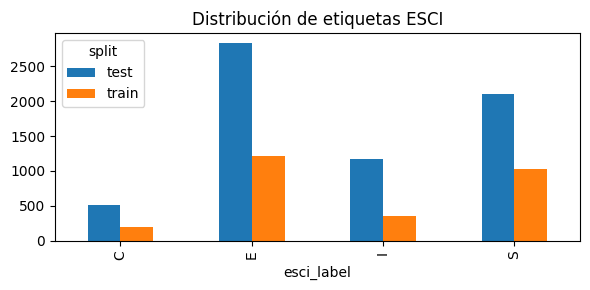

,cobertura de atributos
description,0.524561
bullet_point,0.869987
brand,0.950878
color,0.620159


In [5]:
# ¿Cómo son los datos?
stats = {
    "productos": len(catalog_df),
    "consultas_train": int((queries_df.split == "train").sum()),
    "consultas_test": int((queries_df.split == "test").sum()),
    "pares_anotados": len(qrels_df),
    "candidatos_por_consulta (media)": round(qrels_df.groupby("query_id").size().mean(), 1),
}
display(pd.Series(stats))

lab = qrels_df.merge(queries_df[["query_id", "split"]], on="query_id").pivot_table(
    index="esci_label", columns="split", values="product_id", aggfunc="count")
display(lab)
lab.plot(kind="bar", figsize=(6, 3), title="Distribución de etiquetas ESCI"); plt.tight_layout(); plt.show()

cov = catalog_df[["description", "bullet_point", "brand", "color"]].apply(lambda c: (c.fillna("").str.len() > 0).mean())
display(cov.rename("cobertura de atributos"))

## A2. Tienda simulada

**Qué hace:** crea la tienda en SQLite. ESCI no trae precios ni stock, así que se generan de forma determinista a partir de la semilla y el id de cada producto.

**Qué deberías ver:** 5 productos con precio y stock, y `reproducible: True` (tras `restore(SEED)` la tienda vuelve exactamente al inicio).

In [6]:
from shopassist.store import Store
store = Store(cfg.db_path, catalog_df, seed=cfg.SEED, currency=cfg.currency)
sample_ids = catalog_df.product_id.sample(5, random_state=cfg.SEED).tolist()
display(pd.DataFrame([store.get_product(p) for p in sample_ids])[["product_id", "title", "brand", "price", "stock"]])

,product_id,title,brand,price,stock
0,B07NVLP9CD,AROYI Funda Huawei P30 Lite + Protector de Pan...,AROYI,13.99,31
1,B07BQC7GNL,"Bluetooth Amplificador, Fosi Audio BT20A - Rec...",Fosi Audio,35.99,34
2,B095RWJ9QJ,LHY Magic Stars - Molde de silicona para caram...,LHY,26.99,20
3,B08YDJ23ML,Sykooria Polos Manga Corta Hombre con Cuello a...,Sykooria,12.99,1
4,B07NW282YV,BeMatik - Base de enchufe schuko empotrable IP...,BeMatik,33.99,7


In [7]:
# ¿restore(SEED) deja la tienda igual que al principio?
h0 = store_hash(store)
store.set_stock(sample_ids[0], 0); store.add_to_cart("demo", sample_ids[1], 2)   # ensuciamos la tienda
h1 = store_hash(store)
store.restore(cfg.SEED)
h2 = store_hash(store)
reproducible = h0 == h2
print("inicial:", h0, "| tras cambios:", h1, "| tras restore:", h2, "| reproducible:", reproducible)

inicial: 6d083cc42d4f1739 | tras cambios: 6f6c23b2899d7ea1 | tras restore: 6d083cc42d4f1739 | reproducible: True


## A3. Grabar tu voz

**Qué hace:** graba la voz de referencia para la clonación (15–25 s leyendo `voice/referencia.txt`, tu voz o una voz autorizada) y los audios de los escenarios de voz (guion en `voice/scripts_lectura.md`). Solo graba lo que falte.

**Qué deberías ver:** el texto a leer y el audio de referencia para escucharlo.

> Consejo: copia la carpeta `voice/` a `MyDrive/purchase/voice` para no volver a grabar en otra sesión.

In [8]:
from shopassist.voice import record_audio_colab, upload_audio_colab
print(open("voice/referencia.txt", encoding="utf-8").read())
if IN_COLAB and not os.path.exists("voice/referencia.wav"):
    record_audio_colab(22, "voice/referencia.wav")    # o: upload_audio_colab("voice/referencia.wav")
display(Audio("voice/referencia.wav"))

Esta mañana salí temprano a caminar por el parque. 
El cielo estaba despejado y el aire se sentía fresco.
 Me detuve junto al lago para mirar a los patos,
  y luego seguí hasta la biblioteca,
   donde pasé un buen rato leyendo una novela sobre viajes por la costa.



In [9]:

# Audios de los escenarios de voz (solo los que falten)
from shopassist.scenarios import load_scenarios
SCENARIOS = load_scenarios("scenarios/scenarios.yaml")
voice_turns = [(sc["id"], t) for sc in SCENARIOS if sc.get("voice") for t in sc["turns"]]
faltan = [(i, t) for i, t in voice_turns if not os.path.exists(t["audio"])]
print(f"{len(voice_turns)} audios de escenarios, faltan {len(faltan)}")
if IN_COLAB:
    for sid, t in faltan:
        input(f"[{sid}] Pulsa Enter y lee: «{t['user']}»")
        record_audio_colab(5, t["audio"])

29 audios de escenarios, faltan 0


## A4. Cargar los modelos

**Qué hace:** construye el buscador y carga el LLM, el reconocimiento de voz (ASR) y la síntesis de voz (TTS).

**Qué deberías ver:** la tabla de tiempos de carga y la memoria usada, que debe quedar por debajo de los 15 GB de la T4.

| Componente | Modelo | VRAM aprox. | Por qué |
|---|---|---|---|
| LLM | `Qwen/Qwen2.5-3B-Instruct` fp16 (o 7B en 4 bits) | ~6.5 GB | Buen español y JSON; cabe junto con la voz en una T4 |
| ASR | `faster-whisper small` float16 | ~1 GB | Buen WER en español y rápido; `medium`/`large-v3-turbo` como opción |
| TTS | Coqui XTTS-v2 | ~2 GB | Clonación *zero-shot* en español con 6–30 s de referencia |
| Embeddings | `multilingual-e5-small` | ~0.5 GB | Multilingüe y rápido |
| Re-ranker | `mmarco-mMiniLMv2-L12` | ~0.5 GB | Cross-encoder multilingüe |
| Similitud de voz | ECAPA (SpeechBrain) | ~0.1 GB | Solo para evaluar (C4) |

Total ≈ 10.5–11 GB < 15 GB.

> Licencia XTTS-v2: Coqui Public Model License (uso no comercial / académico).

In [10]:
# Buscador híbrido: BM25 + denso (e5) + fusión RRF + re-ranker
from shopassist.retrieval import build_retriever
retriever = build_retriever(cfg, catalog_df, "hybrid_rerank", store=store)

In [11]:
from shopassist.notebook_utils import load_voice_and_llm
USE_LLM = True       # False -> el agente decide con reglas, sin LLM (sirve sin GPU)
ASR_SIZE = "small"   # o "medium" / "large-v3-turbo"

llm, asr, tts, cold_df = load_voice_and_llm(cfg, use_llm=USE_LLM, asr_size=ASR_SIZE)
display(cold_df)
memory_report("tras cargar LLM + ASR + TTS")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.


,model,load_s,vram_gb_after
0,llm,31.567940,5.748010
1,asr,2.704906,5.748010
2,tts,33.676043,7.498058
0,tts_latentes_ref,3.270998,NaN


{'tag': 'tras cargar LLM + ASR + TTS', 'vram_alloc_gb': 7.5, 'vram_reserved_gb': 7.62, 'vram_total_gb': 14.56, 'ram': ['Mem:            12Gi       5.9Gi       727Mi        18Mi       6.4Gi       6.8Gi']}


{'tag': 'tras cargar LLM + ASR + TTS',
 'vram_alloc_gb': 7.5,
 'vram_reserved_gb': 7.62,
 'vram_total_gb': 14.56,
 'ram': ['Mem:            12Gi       5.9Gi       727Mi        18Mi       6.4Gi       6.8Gi']}

# Parte B · Verlo funcionar

## B1. Buscar productos

**Qué hace:** prueba el buscador con dos consultas.

**Qué deberías ver:** 5 productos por consulta, ordenados por relevancia, con precio y stock.

In [12]:
for q in ["audífonos bluetooth", "funda para móvil"]:
    print("\n>>", q)
    display(pd.DataFrame(retriever.search(q, k=5))[["product_id", "title", "price", "stock", "score"]])


>> audífonos bluetooth


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,product_id,title,price,stock,score
0,B081C31KV4,"Auriculares Bluetooth, 5.0 Auriculares Bluetoo...",51.99,38,5.157586
1,B0813BYJL4,Auriculares Bluetooth Auriculares inalámbricos...,44.99,19,3.013371
2,B07VDY6DT9,"Auriculares Bluetooth 5.0, HOMSCAM Impermeable...",41.99,28,2.757146
3,B0811T76R8,Auriculares Inalámbricos Bluetooth 5.0 con Caj...,24.99,35,2.616197
4,B081N9X9LR,"fghdjjfdh Auriculares Bluetooth, Auriculares B...",55.99,40,2.480207



>> funda para móvil


,product_id,title,price,stock,score
0,B07W545TBG,LeYi Funda Huawei P30 Lite con 2-Unidades Cris...,17.99,27,3.247713
1,B07YCD7G2C,kwmobile Carcasa Compatible con Huawei P30 Pro...,14.99,19,3.111316
2,B07Q1CR88T,kwmobile Carcasa Compatible con Huawei P30 Lit...,10.99,6,3.054577
3,B07F15XSLJ,kwmobile Carcasa Compatible con Apple iPhone S...,10.99,13,2.889094
4,B08XHBK1CF,"Funda Samsung Galaxy S20 FE, Funda Samsung S20...",4.99,6,1.898393


## B2. Conversación por texto

**Qué hace:** una compra completa en 8 turnos. El agente recuerda el presupuesto y las cantidades y elige qué herramienta usar. Las validaciones de cantidad, presupuesto y stock se hacen en código, no en el LLM.

**Qué deberías ver:** la búsqueda, la comparación, el cambio de cantidad, la cotización y **un solo pedido**: el segundo «Confirmo» devuelve el mismo pedido en vez de crear otro.

In [13]:
from shopassist.agent import ShoppingAgent
store.restore(cfg.SEED)
agent = ShoppingAgent(store, retriever, llm=llm, cart_id="demo", cfg=cfg)

for u in ["Mi presupuesto es de 60 euros", "Busco audífonos bluetooth", "Compara el primero y el segundo",
          "Añade dos unidades del primero al carrito", "Mejor que sea una sola unidad",
          "Prepara la cotización", "Confirmo el pedido", "Confirmo el pedido"]:
    show_turn(agent, u); print()
print("Pedidos:", [(o["order_id"], o["total"]) for o in store.list_orders()])

👤 Mi presupuesto es de 60 euros
🤖 No pude completar la operación: Falta el argumento obligatorio 'amount'.
   herramientas: [('set_budget', True), ('set_budget', False), ('set_budget', False), ('set_budget', False), ('set_budget', False), ('set_budget', False), ('set_budget', False)] | tiempos: {'llm_s': 14.72, 'retrieval_s': 0.0, 'tools_s': 0.0, 'total_s': 14.72}

👤 Busco audífonos bluetooth
🤖 Tu pedido incluye 1 unidad de Auriculares Bluetooth, 5.0 Auriculares Bluetooth In Ear Inalámbricos Auricular Estéreo en Oreja Manos Libres con Caja de Carga Portátil para Airpods Android/iPhone (Rosa1). El costo total es de 51.99 EUR. ¿Confirma el pedido?
   herramientas: [('search_products', True), ('add_to_cart', True), ('create_quote', True)] | tiempos: {'llm_s': 11.89, 'retrieval_s': 0.34, 'tools_s': 0.0, 'total_s': 12.23}

👤 Compara el primero y el segundo
🤖 Tu pedido incluye 1 unidad de Auriculares Bluetooth, 5.0 Auriculares Bluetooth In Ear Inalámbricos Auricular Estéreo en Oreja Manos Li

## B3. Un turno completo por voz

**Qué hace:** grabas una pregunta, Whisper la transcribe, el agente responde y XTTS lo lee con tu voz clonada. El cronómetro empieza cuando termina la grabación.

**Qué deberías ver:** la transcripción, la respuesta, el tiempo de cada etapa y el audio de respuesta.

In [15]:
import av
_av_open = av.open
def _av_open_compat(*args, metadata_errors=None, **kwargs):
    return _av_open(*args, **kwargs)
av.open = _av_open_compat

In [18]:
!pip install -q nvidia-cublas-cu12
import ctypes, glob
for name in ["libcublasLt.so.12", "libcublas.so.12"]:
    path = glob.glob(f"/usr/local/lib/python3.13/dist-packages/nvidia/**/{name}", recursive=True)[0]
    ctypes.CDLL(path, mode=ctypes.RTLD_GLOBAL)
    print("cargada", path)

cargada /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublasLt.so.12
cargada /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublas.so.12


In [19]:
from shopassist.latency import VoicePipeline
assert tts is not None, "Falta la voz: graba la referencia en A3 y vuelve a ejecutar A4"
store.restore(cfg.SEED)
voice_agent = ShoppingAgent(store, retriever, llm=llm, cart_id="voz", cfg=cfg)
pipe = VoicePipeline(asr, voice_agent, tts, out_dir="results/voice_demo")

DEMO = "results/voice_demo/pregunta.wav"
if IN_COLAB:
    record_audio_colab(6, DEMO)            # di p.ej.: "Busco una botella de agua de menos de veinte euros"
else:
    DEMO = "voice/scenarios/v1_t1.wav"
rec = pipe.run_turn(DEMO, turn_id="demo1")
print("Transcripción:", rec["transcript"]); print("Respuesta:", rec["reply"])
display(pd.Series(rec["timings"]).round(2))
display(Audio(rec["audio_out"]))

<IPython.core.display.Javascript object>

Transcripción: Busco una botella de agua de menos de 20 euros.
Respuesta: He añadido la botella de agua a tu carrito. El total es 4,99 EUR. ¿Confirma el pedido?


,0
asr_s,1.22
retrieval_s,0.28
llm_s,9.91
tools_s,0.00
tts_s,9.25
agent_other_s,0.00
total_s,20.65


## B4. Demo interactiva por voz (Gradio)

**Qué hace:** abre una interfaz web (enlace público `share=True`) con micrófono. Cada turno pasa por el mismo `VoicePipeline` de B3: Whisper → agente (recuperación + LLM + herramientas) → XTTS con la voz clonada. Cada pestaña del navegador es una sesión con su propio agente y carrito; «Reiniciar sesión» borra la conversación y, si se marca, restaura la tienda con `restore(SEED)`.

**Qué deberías ver:** la transcripción y la respuesta en el chat, el audio de respuesta que se reproduce solo, la espera real del turno (contador de Gradio y tiempos medidos por etapa) y el carrito, los pedidos y el stock leídos de la tienda tras cada turno. Guion sugerido para el video: README, sección «Demo interactiva».

In [ ]:
# Demo interactiva: micrófono -> ASR -> agente -> TTS, con la espera real de cada turno
import importlib.util, subprocess, sys
if importlib.util.find_spec("gradio") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio>=5.0"], check=True)
from shopassist.demo_ui import build_demo
assert tts is not None, "Falta la voz: graba la referencia en A3 y vuelve a ejecutar A4"
try:
    demo.close()                      # si se vuelve a ejecutar la celda
except NameError:
    pass
store.restore(cfg.SEED)
demo = build_demo(lambda cart_id: ShoppingAgent(store, retriever, llm=llm, cart_id=cart_id, cfg=cfg),
                  asr, tts, store, seed=cfg.SEED, out_dir="results/gradio_demo")
demo.queue(default_concurrency_limit=1).launch(share=True, debug=False)   # demo.close() para detenerla

# Parte C · Medirlo

## C1. Calidad de la búsqueda (nDCG@10)

**Qué hace:** compara el sistema completo con BM25 (línea base) y con ablaciones: sin re-ranker, sin denso y solo con el título. Ganancias E=1, S=0.1, C=0.01, I=0. Los parámetros de la fusión se ajustan **solo con `train`**; `test` se reporta una vez.

**Qué deberías ver:** una tabla con nDCG@10 en train y test (con IC95) por sistema, y un gráfico de barras.

In [20]:
from shopassist.evaluation import run_retrieval_experiments, success_analysis
exp = run_retrieval_experiments(cfg, catalog_df, queries_df, qrels_df)
print("Parámetros elegidos en train:", exp["params"])
ret_table = exp["table"]
display(ret_table)
ret_table.to_csv("results/retrieval_table.csv", index=False)
if exp.get("tuning") is not None:
    display(exp["tuning"]["table"].head(10))

Parámetros elegidos en train: {'fusion': 'linear', 'alpha': 0.7}


,sistema,kind,descripcion,ndcg@10_train,n_train,ndcg@10_test,n_test,ic95_test,s_por_consulta
0,Aleatorio,random,Cota inferior: orden aleatorio,0.5359,100,0.5481,250,"[0.520, 0.577]",0.0001
1,BM25 (baseline),bm25,Línea base léxica: BM25 propio sobre título+ma...,0.6870,100,0.7078,250,"[0.679, 0.736]",0.0001
2,BM25 solo título,bm25_title,Ablación del texto indexado (solo título),0.6716,100,0.6995,250,"[0.669, 0.729]",0.0001
3,Denso e5,dense,"multilingual-e5-small, coseno",0.7373,100,0.7444,250,"[0.717, 0.768]",0.0118
4,Híbrido RRF,hybrid,BM25 + denso fusionados (parámetros ajustados ...,0.7254,100,0.7429,250,"[0.717, 0.768]",0.0134
5,Híbrido + re-ranker,hybrid_rerank,Sistema completo: híbrido + cross-encoder mMAR...,0.7557,100,0.7762,250,"[0.749, 0.800]",0.1431
6,BM25 + re-ranker (sin denso),bm25_rerank,Ablación: sin componente denso,0.7557,100,0.7762,250,"[0.749, 0.800]",0.1282


,fusion,k_rrf,ndcg_train,alpha
0,linear,NaN,0.725442,0.7
1,rrf,10.0,0.719644,NaN
2,rrf,30.0,0.719504,NaN
3,rrf,60.0,0.719067,NaN
4,rrf,100.0,0.718967,NaN
5,linear,NaN,0.711785,0.5
6,linear,NaN,0.703559,0.3


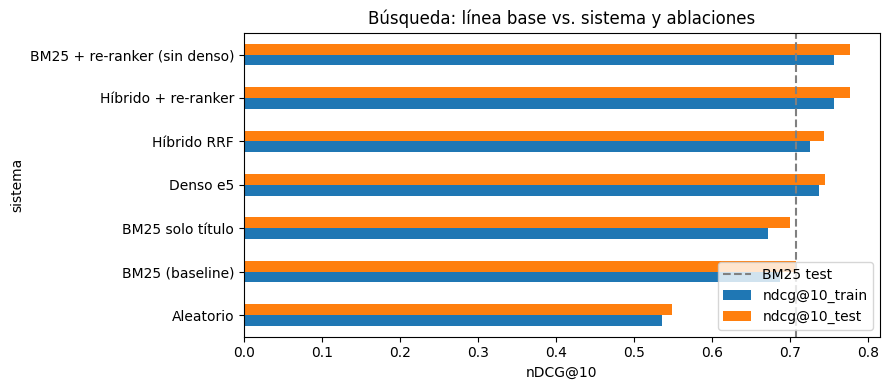

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
t = ret_table.set_index("sistema")[[c for c in ["ndcg@10_train", "ndcg@10_test"] if c in ret_table.columns]]
t.plot(kind="barh", ax=ax)
base = ret_table.loc[ret_table.kind == "bm25", "ndcg@10_test"].iloc[0]
ax.axvline(base, ls="--", c="gray", label="BM25 test")
ax.set_xlabel("nDCG@10"); ax.set_title("Búsqueda: línea base vs. sistema y ablaciones"); ax.legend()
plt.tight_layout(); plt.savefig("results/retrieval_bar.png", dpi=120); plt.show()

## C2. Los 28 escenarios

**Qué hace:** corre 22 escenarios por texto y 6 por voz (`scenarios/scenarios.yaml`), cada uno desde `store.restore(SEED)`. Los de voz se corren dos veces: con el audio real y con la transcripción correcta, para separar los errores del ASR. Todo se guarda en `results/scenarios/<modo>/<id>/`.

**Qué deberías ver:** una fila por escenario con `ok` y los chequeos que fallaron, y la comparación voz vs. transcripción correcta.

In [22]:
from shopassist.scenarios import run_all, scenario_metrics, asr_errors_from_results, compare_voice_vs_gold
def agent_factory():
    return ShoppingAgent(store, retriever, llm=llm, cart_id="c1", cfg=cfg)

df_text, res_text = run_all(SCENARIOS, agent_factory, store, input_mode="text")
display(df_text[["id", "titulo", "voz", "ok", "checks_ok", "checks", "fallidos"]])
print(scenario_metrics(df_text))

,id,titulo,voz,ok,checks_ok,checks,fallidos
0,t01_compra_simple,Compra simple de una funda con pedido confirmado,False,True,4,4,
1,t02_multiproducto_presupuesto,Dos productos distintos dentro de un presupues...,False,True,5,5,
2,t03_presupuesto_insuficiente,"Presupuesto muy bajo, no debe superarse",False,True,3,3,
3,t04_comparar,Comparar las dos primeras opciones de ratón in...,False,True,2,2,
4,t05_consultar_stock,Consultar existencias de un resultado,False,True,2,2,
5,t06_atributo_desconocido,Atributo no verificable debe tratarse como des...,False,False,1,2,reply_contains_any(no contiene)
6,t07_referencia_ambigua,"""Añade eso"" sin contexto requiere aclaración",False,True,3,3,
7,t08_solicitud_vaga,Solicitud sin producto requiere aclaración,False,True,2,2,
8,t09_cambio_cantidad,Cambiar la cantidad de un artículo del carrito,False,True,2,2,
9,t10_quitar_del_carrito,Quitar un producto del carrito,False,False,1,3,op_called(remove_from_cart no llamada); cart_e...


{'escenarios': 28, 'correctos': 19, 'pct_correctos': np.float64(67.9), 'budget_exceeded': 0, 'stock_negative': 0, 'order_without_confirmation': 0, 'duplicate_orders': 0, 'stock_inconsistent': 0, 'violaciones_restricciones': 0}


In [23]:
df_voice, res_voice = run_all(SCENARIOS, agent_factory, store, input_mode="voice", asr=asr, tts=tts)
df_gold, res_gold = run_all(SCENARIOS, agent_factory, store, input_mode="gold_transcript")
display(df_voice[["id", "ok", "fallidos", "error"]])
cmp = compare_voice_vs_gold(df_voice, df_gold); display(cmp)
for r in res_voice:
    print(f"\n=== {r['id']} ===")
    for t in r["turns"]:
        print(f"  [{t['turn']+1}] correcto: {t['user_gold']}\n      asr     : {t['user_text']}\n      bot     : {t['reply'][:160]}")

,id,ok,fallidos,error
0,v1_compra_confirmada,True,,
1,v2_aclaracion,True,,
2,v3_cambio_cantidad,False,qty_of_item(cantidad=3),
3,v4_agotado,False,any_of(sin alternativa | no contiene); cart_qt...,
4,v5_correccion_transcripcion,False,qty_of_item(cantidad=None),
5,v6_stock_cambia_y_reconfirmacion,False,reply_contains_any(no contiene),


,id,ok_voz,fallidos_voz,ok_gold,fallidos_gold,fallo_atribuible_asr
0,v1_compra_confirmada,True,,True,,False
1,v2_aclaracion,True,,True,,False
2,v3_cambio_cantidad,False,qty_of_item(cantidad=3),False,qty_of_item(cantidad=1),False
3,v4_agotado,False,any_of(sin alternativa | no contiene); cart_qt...,False,"cart_qty_le_stock(excesos=[('B08QVJV76V', 1, 0)])",False
4,v5_correccion_transcripcion,False,qty_of_item(cantidad=None),False,qty_of_item(cantidad=10),False
5,v6_stock_cambia_y_reconfirmacion,False,reply_contains_any(no contiene),False,reply_contains_any(no contiene),False



=== v1_compra_confirmada ===
  [1] correcto: Busco una botella de agua, mi presupuesto es de cuarenta euros
      asr     : Busco una botella de agua. Mi presupuesto es de 40 euros.
      bot     : He añadido una botella de agua a tu carrito. El precio es 4,99 EUR. ¿Confirmas el pedido?
  [2] correcto: Añade dos unidades del primero al carrito
      asr     : Añade dos unidades del primero al carrito.
      bot     : Entendí: comprar 2 × «carrito». ¿Es correcto? Responde «sí» o corrígeme (por ejemplo: «no, dije dos»).
  [3] correcto: Sí, es correcto
      asr     : Sí, es correcto.
      bot     : No pude completar la operación: Falta el argumento obligatorio 'product_id'.
  [4] correcto: Prepara la cotización
      asr     : Prepara la cotización.
      bot     : Tu carrito tiene un total de 4,99 EUR. ¿Confirmas el pedido?
  [5] correcto: Sí, confirmo el pedido
      asr     : Sí, confiero en el pedido.
      bot     : ¡Listo! Pedido O00001 registrado por 4,99 euros. Inventario actua

## C3. Métricas de escenarios y errores del ASR

**Qué hace:** calcula el % de escenarios correctos, los incumplimientos (presupuesto superado, stock negativo, pedido sin confirmación, duplicados) y los errores del ASR en cantidades, importes y productos.

**Qué deberías ver:** una tabla por modo (texto, voz, transcripción correcta) y el detalle de errores del ASR.

In [24]:
from shopassist.voice_eval import summarize_asr_errors
metrics_df = pd.DataFrame([{"modo": name, **scenario_metrics(d)} for name, d in
                           [("texto (22+6)", df_text), ("voz (audio)", df_voice), ("voz (transcripción correcta)", df_gold)]])
display(metrics_df)
asr_err = asr_errors_from_results(res_voice)
asr_summary = summarize_asr_errors(asr_err)
display(asr_err[["id", "gold", "hyp", "wer", "qty_errors", "amount_errors", "product_missing"]])
display(pd.Series(asr_summary))

,modo,escenarios,correctos,pct_correctos,budget_exceeded,stock_negative,order_without_confirmation,duplicate_orders,stock_inconsistent,violaciones_restricciones
0,texto (22+6),28,19,67.9,0,0,0,0,0,0
1,voz (audio),6,2,33.3,0,0,0,0,0,0
2,voz (transcripción correcta),6,2,33.3,0,0,0,0,0,0


,id,gold,hyp,wer,qty_errors,amount_errors,product_missing
0,v1_compra_confirmada_t1,"Busco una botella de agua, mi presupuesto es d...",Busco una botella de agua. Mi presupuesto es d...,0.000000,0,0,[]
1,v1_compra_confirmada_t2,Añade dos unidades del primero al carrito,Añade dos unidades del primero al carrito.,0.000000,0,0,[]
2,v1_compra_confirmada_t3,"Sí, es correcto","Sí, es correcto.",0.000000,0,0,[]
3,v1_compra_confirmada_t4,Prepara la cotización,Prepara la cotización.,0.000000,0,0,[]
4,v1_compra_confirmada_t5,"Sí, confirmo el pedido","Sí, confiero en el pedido.",0.500000,0,0,[]
5,v2_aclaracion_t1,Añade eso al carrito,Añade eso al carrito.,0.000000,0,0,[]
6,v2_aclaracion_t2,Busco audífonos bluetooth,Busco abdífonos Bluetooth.,0.333333,0,0,[audifonos]
7,v3_cambio_cantidad_t1,"Mi presupuesto es de treinta euros, busco un c...",Mi presupuesto es de 30 euros. Busco un cuadrado.,0.111111,0,0,[cuaderno]
8,v3_cambio_cantidad_t2,Añade tres unidades del primero al carrito,Añade tres unidades del primero al carrito.,0.000000,0,0,[]
9,v3_cambio_cantidad_t3,"Sí, es correcto","Sí, es correcto.",0.000000,0,0,[]


,0
enunciados,29.000000
wer_corpus,0.103704
cer_corpus,0.056319
errores_cantidad,1.000000
cantidades_total,6.000000
errores_importe,0.000000
importes_total,3.000000
errores_producto,5.000000
palabras_producto_total,20.000000


## C4. Calidad de la voz clonada

**Qué hace:** sintetiza 6 respuestas típicas (distintas del texto de referencia) y mide si se entienden (WER/CER de Whisper) y cuánto se parecen a tu voz (coseno ECAPA), comparado con una voz de fábrica de XTTS.

**Qué deberías ver:** WER/CER y similitud por frase, y un audio de ejemplo.

In [30]:
import huggingface_hub, huggingface_hub.file_download as hf_fd, speechbrain.utils.fetching as sbf
_hf_dl = hf_fd.hf_hub_download          # la original, siempre
def _hf_dl_compat(*args, use_auth_token=None, **kwargs):
    if use_auth_token not in (None, False) and "token" not in kwargs:
        kwargs["token"] = use_auth_token
    try:
        return _hf_dl(*args, **kwargs)
    except Exception as e:
        if "EntryNotFound" in type(e).__name__:
            raise ValueError("File not found on HF hub") from e
        raise
huggingface_hub.hf_hub_download = _hf_dl_compat
if hasattr(sbf, "hf_hub_download"):
    sbf.hf_hub_download = _hf_dl_compat

In [31]:
from shopassist.voice_eval import evaluate_voice_quality, SpeakerEncoder
texts_eval = [
    "He encontrado tres botellas de agua por menos de veinte euros. La primera cuesta doce con cincuenta.",
    "Tu carrito tiene dos unidades y el total es de veinticinco euros con noventa céntimos.",
    "Ese producto está agotado. Te propongo una alternativa similar de la misma marca.",
    "¿Quieres que confirme el pedido? El total está dentro de tu presupuesto.",
    "No puedo verificar si es resistente al agua; ese dato no aparece en la ficha del producto.",
    "Pedido confirmado. El número de pedido es O cero cero cero uno.",
]
vq_detail, vq_summary = evaluate_voice_quality(tts, asr, texts_eval, out_dir="results/voice_quality", encoder=SpeakerEncoder())
display(vq_summary); display(vq_detail[["id", "voz", "wer", "cer", "sim_ref"]])
display(Audio(vq_detail.iloc[0]["wav"]))

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/content/purchase/pretrained_models/spkrec-ecapa-voxceleb/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch custom.py: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for _save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for _load
DEBUG:speechbrain.utils.checkpoints:Registered parameter transfer hook for _load
/usr/local/lib/python3.13/dist-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint save hook for save
DEBUG:speechbrain.utils.checkpoints:Registered checkpoint load hook for load_if_possible
DEBUG:speechbrain.utils.pa

embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/embedding_model.ckpt' -> '/content/purchase/pretrained_models/spkrec-ecapa-voxceleb/embedding_model.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["embedding_model"] = /content/purchase/pretrained_models/spkrec-ecapa-voxceleb/embedding_model.ckpt
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/mean_var_norm_emb.ckpt' -> '/content/purchase/pretrained_models/spkrec-ecapa-voxceleb/mean_var_norm_emb.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["mean_var_norm_emb"] = /content/purchase/pretrained_models/spkrec-ecapa-voxceleb/mean_var_norm_emb.ckpt
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


... (3 outputs left out)

label_encoder.txt:   0%|          | 0.00/129k [00:00<?, ?B/s]

DEBUG:speechbrain.utils.fetching:Fetch: Local file found, creating symlink '/root/.cache/huggingface/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/label_encoder.txt' -> '/content/purchase/pretrained_models/spkrec-ecapa-voxceleb/label_encoder.ckpt'
DEBUG:speechbrain.utils.parameter_transfer:Set local path in self.paths["label_encoder"] = /content/purchase/pretrained_models/spkrec-ecapa-voxceleb/label_encoder.ckpt
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder
DEBUG:speechbrain.utils.parameter_transfer:Redirecting (loading from local path): embedding_model -> /content/purchase/pretrained_models/spkrec-ecapa-voxceleb/embedding_model.ckpt
DEBUG:speechbrain.utils.parameter_transfer:Redirecting (loading from local path): mean_var_norm_emb -> /content/purchase/pretrained_models/spkrec-ecapa-voxceleb/mean_var_norm_emb.ckpt
DEBUG:speechbrain.utils.parameter_

,voz,wer_mean,wer_std,cer_mean,cer_std,sim_ref_mean,sim_ref_std
0,base_Claribel Dervla,0.068,0.133,0.023,0.045,-0.046,0.035
1,clonada,0.120,0.127,0.055,0.060,0.661,0.034
2,referencia_mitad_vs_mitad,NaN,NaN,NaN,NaN,0.814,NaN


,id,voz,wer,cer,sim_ref
0,0,clonada,0.000000,0.000000,0.701881
1,0,base_Claribel Dervla,0.000000,0.000000,-0.067525
2,1,clonada,0.066667,0.043478,0.634686
3,1,base_Claribel Dervla,0.000000,0.000000,-0.037259
4,2,clonada,0.153846,0.038961,0.693819
5,2,base_Claribel Dervla,0.076923,0.025974,-0.029321
6,3,clonada,0.166667,0.086957,0.653393
7,3,base_Claribel Dervla,0.000000,0.000000,-0.046088
8,4,clonada,0.000000,0.000000,0.667709
9,4,base_Claribel Dervla,0.000000,0.000000,-0.098675


## C5. Tiempos: arranque y latencia por turno

**Qué hace:** mide cuánto tarda en construirse cada buscador y el tiempo por etapa (ASR, búsqueda, LLM, herramientas, TTS) desde el fin de la grabación hasta el audio, separando el arranque en frío de los turnos siguientes.

**Qué deberías ver:** una tabla de construcción de índices, otra de latencia (media / p90) y un gráfico por etapa.

In [32]:
# Tiempo de construcción de cada buscador
load_times = []
for kind in ["bm25", "dense", "hybrid", "hybrid_rerank"]:
    t0 = time.perf_counter()
    r = build_retriever(cfg, catalog_df, kind, store=store)
    r.search("calentar", k=1)  # fuerza la carga de los modelos
    load_times.append({"recuperador": kind, "construccion_s": round(time.perf_counter() - t0, 2)})
display(pd.DataFrame(load_times))

,recuperador,construccion_s
0,bm25,0.00
1,dense,0.02
2,hybrid,0.02
3,hybrid_rerank,0.36


,fase,estadistico,n,asr_s,retrieval_s,llm_s,tools_s,tts_s,agent_other_s,total_s,vram_gb_after
0,caliente,media,11,0.625,0.095,5.192,0.000,5.231,0.001,11.145,NaN
1,caliente,mediana,11,0.587,0.000,4.236,0.000,5.400,0.001,9.622,NaN
2,caliente,p90,11,0.730,0.269,8.550,0.000,8.597,0.002,14.982,NaN
3,primer_turno,media,1,0.691,0.268,9.662,0.001,3.856,0.002,14.480,NaN
4,primer_turno,mediana,1,0.691,0.268,9.662,0.001,3.856,0.002,14.480,NaN
5,primer_turno,p90,1,0.691,0.268,9.662,0.001,3.856,0.002,14.480,NaN
6,todos,media,12,0.630,0.110,5.565,0.000,5.116,0.001,11.423,NaN
7,todos,mediana,12,0.588,0.000,4.976,0.000,5.149,0.001,9.730,NaN
8,todos,p90,12,0.727,0.269,9.551,0.001,8.454,0.002,14.932,NaN
9,carga_llm,valor,1,NaN,NaN,NaN,NaN,NaN,NaN,31.568,5.748


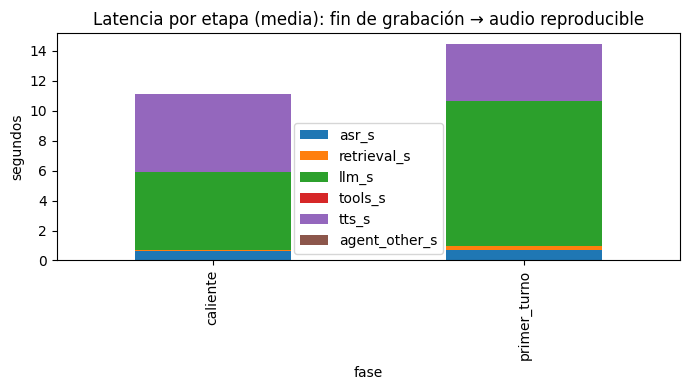

In [33]:
# Latencia con turnos "calientes" usando los audios de los escenarios
from shopassist.latency import latency_summary, plot_latency
store.restore(cfg.SEED)
pipe = VoicePipeline(asr, ShoppingAgent(store, retriever, llm=llm, cart_id="lat", cfg=cfg), tts, out_dir="results/latency")
for sc in [s for s in SCENARIOS if s.get("voice")][:3]:
    for t in sc["turns"]:
        if os.path.exists(t["audio"]):
            pipe.run_turn(t["audio"], turn_id=f"{sc['id']}_{t['audio'][-6:-4]}")
lat = latency_summary(pipe.history, load_timings=cold_df.to_dict("records"))
display(lat.round(3))
lat.to_csv("results/latency_summary.csv", index=False)
plot_latency(lat); plt.savefig("results/latency_bar.png", dpi=120); plt.show()

## C6. 5 aciertos y 5 fallos

**Qué hace:** elige automáticamente las 5 mejores y 5 peores consultas de `test` (nDCG@10 del sistema completo) y los escenarios correctos y fallidos.

**Qué deberías ver:** las tablas de aciertos y fallos y, para cada fallo, qué esperaba el dataset y qué devolvió el sistema. **Completa las causas** en `REPORTE.md` (sinónimos, marcas, falta de atributos, errores de ASR en números…).

In [34]:
full = [k for k in exp["results"] if "re-ranker" in k and "BM25" not in k][0]
sa = success_analysis(exp["results"][full]["test"]["per_query"], n=5)
print("Aciertos (búsqueda):"); display(sa["best"])
print("Fallos (búsqueda):"); display(sa["worst"])

cat_idx = catalog_df.set_index("product_id")
def explain(qid):
    g = qrels_df[qrels_df.query_id == qid]
    exact = g[g.esci_label == "E"].product_id.head(2).tolist()
    top = exp["results"][full]["test"]["per_query"].set_index("query_id").loc[qid, "top3"]
    return {"exactos": [cat_idx.loc[p, "title"][:80] for p in exact], "top3_sistema": [cat_idx.loc[p, "title"][:80] for p in top]}
for qid in sa["worst"].query_id[:5]:
    print(qid, json.dumps(explain(qid), ensure_ascii=False, indent=1))

Aciertos (búsqueda):


,query_id,query,ndcg,n_candidates,n_exact,top3_gains
0,5378,8gb 512gb,1.0,39,27,"[1.0, 1.0, 1.0]"
1,8035,alisado sin formol,1.0,40,27,"[1.0, 1.0, 1.0]"
2,11004,atornillador sin escobillas,1.0,40,31,"[1.0, 1.0, 1.0]"
3,15979,biombo blanco barato,1.0,40,25,"[1.0, 1.0, 1.0]"
4,16154,bisagras para puertas de armarios,1.0,40,34,"[1.0, 1.0, 1.0]"


Fallos (búsqueda):


,query_id,query,ndcg,n_candidates,n_exact,top3_gains
0,78694,pen f olympus,0.068514,40,3,"[0.1, 0.01, 0.01]"
1,82056,pompom mini,0.128570,16,3,"[0.0, 0.0, 0.0]"
2,37290,elevadores de coches de 2 columnas,0.186096,40,3,"[0.0, 0.0, 0.0]"
3,7789,album guardería,0.210688,39,15,"[0.1, 0.1, 0.0]"
4,50658,hilo soldar sin gas 1mm,0.220669,40,5,"[0.1, 0.0, 0.1]"


78694 {
 "exactos": [
  "Entatial Anillo Adaptador de Lente OM ‑ M4/3 para Lente de Montura OM de para Ol",
  "DURAGADGET Funda Negra Y Roja para Cámara Fujifilm X-T2 / Olympus OM-D E-M1 Mark"
 ],
 "top3_sistema": [
  "Olympus Pen E-PL5 - Cámara Evil de 17.2 MP (Pantalla 3\", estabilizador óptico, v",
  "DURAGADGET Funda De Neopreno para Cámara Olympus Pen F + Gamuza Limpiadora - ¡Id",
  "DURAGADGET Bolso para la cámara fotográfica Olympus OM-D E-M5 Mark II | Pen E-PL"
 ]
}
82056 {
 "exactos": [
  "SUPVOX 200 unids Pompoms Fuzzy Pom Poms Bolas para Decoraciones de Artesanía Bri",
  "SUPVOX 100 unids Pompoms Multicolor Fuzzy Pom Poms Bolas para DIY Crafts Decorac"
 ],
 "top3_sistema": [
  "Cloak Poncho Cape Estilo Manga 3/4 Manga Estilo Kimono Pompom Minivestido Mini C",
  "Sombreroshop Bufanda de Mujer Mini Pompom pañuelo verano (talla única - blanco)",
  "TiaoBug Mini Vestido de Pom-Pom Niñas Mujer Uniforme Escolar Colegio de Animador"
 ]
}
37290 {
 "exactos": [
  "2 Piezas Coche Reso

In [35]:
all_sc = pd.concat([df_text.assign(modo="texto"), df_voice.assign(modo="voz")])
failed_sc = all_sc[~all_sc.ok][["modo", "id", "titulo", "fallidos"]]
print("Escenarios correctos:"); display(all_sc[all_sc.ok].head(5)[["modo", "id", "titulo"]])
print("Escenarios fallidos:"); display(failed_sc.head(10))

Escenarios correctos:


,modo,id,titulo
0,texto,t01_compra_simple,Compra simple de una funda con pedido confirmado
1,texto,t02_multiproducto_presupuesto,Dos productos distintos dentro de un presupues...
2,texto,t03_presupuesto_insuficiente,"Presupuesto muy bajo, no debe superarse"
3,texto,t04_comparar,Comparar las dos primeras opciones de ratón in...
4,texto,t05_consultar_stock,Consultar existencias de un resultado


Escenarios fallidos:


,modo,id,titulo,fallidos
5,texto,t06_atributo_desconocido,Atributo no verificable debe tratarse como des...,reply_contains_any(no contiene)
9,texto,t10_quitar_del_carrito,Quitar un producto del carrito,op_called(remove_from_cart no llamada); cart_e...
11,texto,t12_agotado_alternativa,"Producto agotado al añadir, se propone alterna...",alternative_proposed(sin alternativa); cart_qt...
20,texto,t21_cantidad_invalida,Cantidad cero no se añade al carrito,cart_empty(items=1)
21,texto,t22_ver_carrito,Ver el carrito con dos artículos,qty_of_item(cantidad=1)
24,texto,v3_cambio_cantidad,Voz: cambio de cantidad conservando el presupu...,qty_of_item(cantidad=1)
25,texto,v4_agotado,"Voz: producto agotado, se busca alternativa o ...","cart_qty_le_stock(excesos=[('B08QVJV76V', 1, 0)])"
26,texto,v5_correccion_transcripcion,Voz: corrección de la transcripción antes de e...,qty_of_item(cantidad=10)
27,texto,v6_stock_cambia_y_reconfirmacion,Voz: cambio de stock entre cotización y confir...,reply_contains_any(no contiene)
2,voz,v3_cambio_cantidad,Voz: cambio de cantidad conservando el presupu...,qty_of_item(cantidad=3)


### Limitaciones (completar con lo observado)
* La NLU basada en reglas cubre un vocabulario acotado; el LLM de 3B puede elegir mal herramientas en peticiones largas.
* Atributos que no están en la ficha (resistencia al agua, compatibilidad) se reportan como *desconocidos*.
* El ASR confunde números parecidos (catorce/cuarenta) y marcas en inglés; por eso el agente repite lo entendido antes de comprar.
* Precios y stock son sintéticos; el catálogo es un subconjunto de ESCI.
* La clonación *zero-shot* depende mucho de la calidad de la grabación de referencia.

## C7. Reporte automático

**Qué hace:** junta todas las tablas de las partes A y C en `results/REPORTE_auto.md`.

**Qué deberías ver:** el mensaje `results/REPORTE_auto.md escrito`. Copia los números a la plantilla del README (§8).

In [36]:
REPORT = {
    "datos": checks, "stats": stats, "etiquetas": lab, "restore_reproducible": reproducible,
    "carga_indices": pd.DataFrame(load_times), "carga_modelos": cold_df,
    "recuperacion": ret_table,
    "escenarios": metrics_df, "asr_errores": pd.Series(asr_summary).to_frame("valor"), "voz_vs_gold": cmp,
    "calidad_voz": vq_summary, "latencia": lat.round(3),
    "aciertos_recuperacion": sa["best"], "fallos_recuperacion": sa["worst"], "escenarios_fallidos": failed_sc,
}
write_report(REPORT, "results/REPORTE_auto.md")

results/REPORTE_auto.md escrito
